<div style="text-align: center; font-size: 32px">
Aula 04 - O Qiskit (Quantum Information Science Kit)
</div>

O Qiskit é um kit de desenvolvimento de software, criado originalmente pela IBM, com início em em 2017, para construir, simular e executar programas de computação quântica usando Python. Com ele, você pode:

- criar circuitos quânticos;
- aplicar portas como Hadamard, CNOT, \(R_x\) e \(R_z\);
- simular circuitos em um computador convencional;
- executar circuitos em computadores quânticos;
- analisar medições e visualizar resultados;
- implementar algoritmos completos.

  O objetico dessa aula é deixar você familiarizado com o ambiente de desenvolvimento e adquirir uma coleção de pequenos códigos com funcionalidades que serão utilizadas nos algoritmos.

## 01 - Imports
Abaixo está uma série de imports que você deverá usar ao desenvolver e analisar os algoritmos de computação quântica. 


In [30]:
from math import pi, gcd #(util para o algoritmo de Shor)

#apemas para operacoes e representacoes matemáticas
from fractions import Fraction
import numpy as np

#qiskit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.visualization import plot_histogram
from qiskit.quantum_info import Statevector
from qiskit.visualization import array_to_latex

try:
    from qiskit_aer import AerSimulator
    backend = AerSimulator()
    print(":-)")
except Exception:
    backend = None
    print(":-(")

print("Importações carregadas!")

:-)
Importações carregadas!


## 02 - Inicialização de um circuito quântico
Aqui você irá definir quais qubits começão em o e quais em 1. Essas definicões dependem do algoritmo que está sendo implementado.

In [32]:
n=3
qc=QuantumCircuit(n,n)  # nesse caso, nosso circuito será consituído de 4 qubits e 4 bits clássicos. Os bits clássicos têm a funcão
                        #de armazenar a leitura dos qubits,
                        #quando observados
                        #o circuito foi denominado "qc", quando escrever qc.(a), estará se referindo ao aésimo qubit, sendo o qc(0) o menos significativo     



qc.x(1)         # setando o estado inicial dos bit 1  em 1. Os demais em zero.
               
qc.barrier()   #Sempre podemos criar barreiras para organizar nosso circuito, marcando um estado. Isso é uma boa prárica. 

print("Inicializado")
                

Inicializado


## 03 - Desenvolvimento do algoritmo
Sequencialmente, você pode aplicar portas quânticas aos qubits. 

In [33]:
qc.h(2)  # aplicamos Hadamard ao qubit 2. 
qc.cx(2,1)  # aplicamos uma inversão controlada no qubit 1 (alvo). Controlada pelo qubit 2. 

qc.crx(np.pi/3,2,0)   # aplicamos uma inversão controlada de 60 graus no qubit 0. Controlada pelo qubit 2.
qc.rx(np.pi/3,1)   # aplicamos uma inversão no qubit 1. 

qc.barrier()  #Isso é uma boa prárica. 
print("Parte 01 implementada")

Parte 01 implementada


## 04 - Visualização do circuito

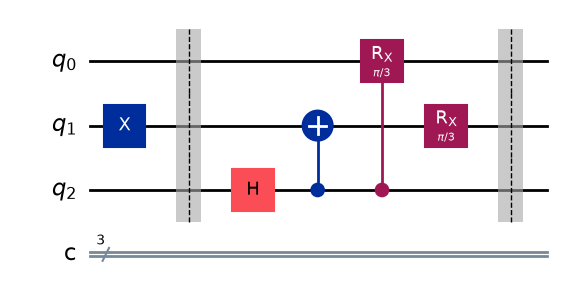

In [34]:
qc.draw('mpl')   #se tudo estiver correto, isso fará uma imagem do seu circuito. 

## 05 - Analisando estados. 
Vamos agora analisar o vetor estado do circuito na segunda barreira. 

In [35]:
# Estado final
sv = Statevector.from_instruction(qc) # isso calcula o vetor de estados

# Transforma em vetor-coluna , por estética
sv_coluna = np.asarray(sv).reshape(-1, 1)

display(array_to_latex(sv_coluna, precision=2,max_size=100))  # aqui são perfumagens em latex para ficar bonito e precisao desejada no print

<IPython.core.display.Latex object>

## 06 - Separando módulos e fases
Aqui você irá observar os módulos dos estados, que dão a raiz das probabilidades. E também as fases, separadamente

In [ ]:
display(array_to_latex(np.abs(sv_coluna), precision=2,max_size=100))  # módulo dos estados
display(array_to_latex(np.angle(sv_coluna), precision=2,max_size=100))  # fase dos estados


<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

## 07 - Execução no simulador e medição
Aqui vamos simular a execução do circuito em um computador quântico e medir a saída. Faremos milhares de execuções, cada uma resultando numa medida que seguem as probabilidades dos estados (raíz quadrada dos módulos). Repare que só há possibilidades de 4 saidas:

- 000 com probabilidade    aproximadamente 12%
- 010 com probabilidade    aproximadamente 37% 
- 100 com probabilidade    aproximadamente 28%
- 101 com probabilidade    aproximadamente 10%
- 110 com probabilidade    aproximadamente 10%
- 111 com probabilidade    aproximadamente 3%


{'110': 882, '111': 290, '101': 917, '100': 2818, '000': 1289, '010': 3804}


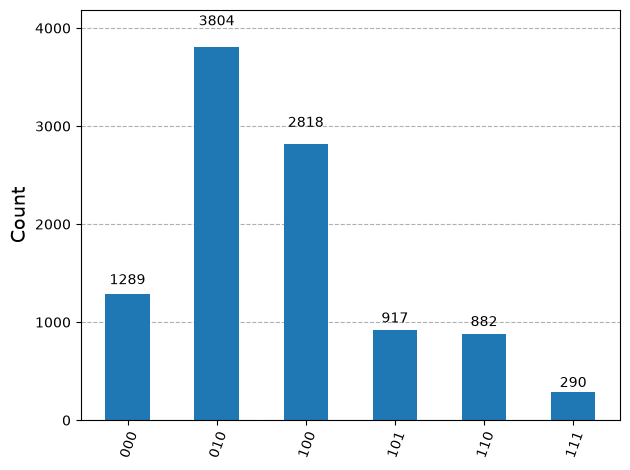

qiskit_aer gerou a saídas.


In [37]:
counts = None
qc.measure(range(n), range(n))  #as medicoes dos n qubits irao colapsar e ser registrada cada uma num bit classico

if backend is not None:
    tqc = transpile(qc, backend) # A função transpile traduz e otimiza o circuito qc para que ele seja compatível com o backend.
                                 # Um backend pode aceitar apenas determinadas portas.
                        #Muitas vezes o backend utiliza uma sequência de portas mais simples para executar uma porta mais complexa oferecida pelo qiskit.              

    result = backend.run(tqc, shots=10000).result() # Esse comando envia o circuito transpilado para execução no backend. estamos usando o AerSimulator
                                                   # mas poderia ser outro, inclusive um compudar quantico real.     
    counts = result.get_counts()                   # aguarda a conclusão da execução e obtém o objeto Result contendo os dados produzidos pelo backend.
    print(counts)
    try:
        display(plot_histogram(counts))
        print("qiskit_aer gerou a saídas.")
    except Exception:
        pass
else:
    print("qiskit_aer não está disponível neste ambiente.")



## 08 - Print do circuito completo, com a medição
Veja como seria a representação da medição final!

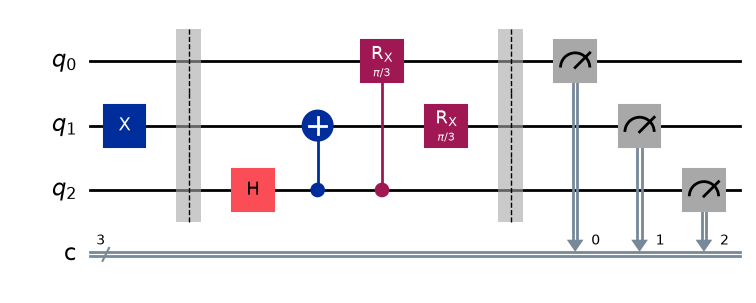

In [38]:
qc.draw('mpl')